# Aplicación final: reconstruir una imagen desconocida

En los primeros ejercicios utilizamos un modelo binario, en el que cada entrada de $A$ indicaba solamente si el centro de un píxel pertenecía o no a un rayo. En este último ejercicio abandonaremos ese modelo simplificado y utilizaremos una matriz de proyección basada en la geometría de los rayos. La entrada $a_{rj}$ representa la longitud del tramo del rayo $r$ contenido dentro del píxel $j$. Por lo tanto, todo píxel atravesado por el rayo contribuye a la medición de manera proporcional a la longitud recorrida en su interior:

$$b_r = \sum_j a_{rj}\,x_j$$

El archivo `datos_tomografia_final_128.npz` contiene mediciones simuladas de una imagen desconocida de $128 \times 128$ píxeles. Incluye la resolución $n$, la matriz de proyección dispersa $A$, el vector de mediciones ruidosas $b$, los ángulos $\theta_0, \dots, \theta_{K-1}$, las posiciones de detector $s_0, \dots, s_{q-1}$ y una estimación del ruido. Las filas de $A$ y las componentes de $b$ están ordenadas primero por ángulo y luego por posición de detector, por lo que la fila $r = kq + j$ corresponde al rayo $(\theta_k, s_j)$.

In [ ]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt


#### a) Cargar los datos y determinar $K$ y $q$ a partir de las cantidades de ángulos y posiciones de detector. Verificar que $A \in \mathbb{R}^{Kq \times n^2}$ y que $b \in \mathbb{R}^{Kq}$.

In [3]:
# Función provista por la cátedra (archivo cargar_datos_tomografia.py, en la misma carpeta)
from cargar_datos_tomografia import cargar_datos_tomografia

datos = cargar_datos_tomografia('datos_tomografia_final_128.npz')

n = datos['n']
A = datos['A'].astype(float)          # matriz dispersa (sigue siendo dispersa; se pasa a float64)
b = datos['b'].astype(float)          # mediciones ruidosas
angulos = datos['angulos']            # theta_0, ..., theta_(K-1)
posiciones = datos['posiciones_detector']   # s_0, ..., s_(q-1)
norma_ruido = datos['norma_ruido_esperada'] # estimación de la norma del ruido

K = len(angulos)       # cantidad de ángulos
q = len(posiciones)    # cantidad de posiciones de detector

print(f"n = {n}, K = {K}, q = {q}")
print(f"Dimensión de A {A.shape}  (esperado: ({K * q}, {n**2}))")
print(f"Dimensión de b {b.shape}  (esperado: ({K * q},))")
print("¿A ∈ R^(Kq x n²)?", A.shape == (K * q, n**2))
print("¿b ∈ R^(Kq)?    ", b.shape == (K * q,))
print(f"Estimación de la norma del ruido: {norma_ruido:.2f}")

n = 128, K = 90, q = 183
Dimensión de A (16470, 16384)  (esperado: (16470, 16384))
Dimensión de b (16470,)  (esperado: (16470,))
¿A ∈ R^(Kq x n²)? True
¿b ∈ R^(Kq)?     True
Estimación de la norma del ruido: 75.97


Se cargaron los datos con la función `cargar_datos_tomografia` provista por la cátedra, que devuelve $A$ como matriz dispersa (se guardan solo los valores distintos de 0).

$K$ es la cantidad de ángulos y $q$ la cantidad de posiciones del detector
Como $K = 90$ y $q = 183$ se sabe que hay $Kq = 16470$ rayos en total y cada rayo es una medici'on. A su vez Se verificó que $A \in \mathbb{R}^{16470 \times 16384}$, es decir tiene una fila por rayo y una columna por cada uno de los $128^2 = 16384$ píxeles de la imagen, y que $b \in \mathbb{R}^{16470}$, una medición por rayo.

Es la misma estructura del Ejercicio 3, pero con muchos más rayos y píxeles.

#### b) Organizar las mediciones en una matriz $S \in \mathbb{R}^{K \times q}$ utilizando $S_{kj} = b_{kq+j}$. Visualizar $S$ como un sinograma, indicando en sus ejes los valores de $s$ y $\theta$.

Dimensión de S: (90, 183)
¿S[k, j] = b[k*q + j]? True


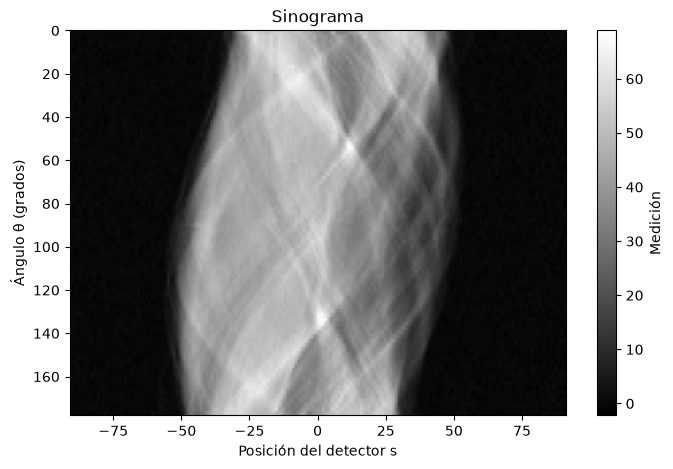

In [ ]:
# S[k, j] = b[k*q + j]
# Como b está ordenado por ángulo y luego por detector, alcanza con un reshape por filas
S = b.reshape(K, q)
print("Dimensión de S:", S.shape)
print("¿S[k, j] = b[k*q + j]?", S[5, 10] == b[5 * q + 10])

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(S, cmap='gray', aspect='auto',
               extent=[posiciones[0], posiciones[-1], np.degrees(angulos[-1]), np.degrees(angulos[0])])
ax.set_xlabel('Posición del detector s')
ax.set_ylabel('Ángulo θ (grados)')
ax.set_title('Sinograma')
fig.colorbar(im, ax=ax, label='Medición')
plt.savefig('figuras/ejercicio_10b.png', dpi=150, bbox_inches='tight')
plt.show()

Como las componentes de $b$ están ordenadas primero por ángulo y luego por posición del detector, las primeras $q$ mediciones corresponden al primer ángulo, las siguientes $q$ al segundo, y así sucesivamente. Por eso, armar $S$ con $S_{kj} = b_{kq+j}$ es lo mismo que hacer `b.reshape(K, q)`, es decir el mismo formato por filas del Ejercicio 1. Cada fila de $S$ es la proyección de un ángulo y cada columna, una posición del detector.

El sinograma es la matriz $S$ dibujada como imagen:

- cada fila es un ángulo $\theta$ (eje vertical);
- cada columna es una posición del detector $s$ (eje horizontal);
- el brillo de cada punto es la medición de ese rayo. Cuanto más claro, más atenuación acumuló.

Se ven curvas que se cruzan. Esto ocurre porque un punto $p = (u_0, v_0)$ del objeto es atravesado por el rayo con $s = u_0\cos\theta + v_0\sin\theta$ (la ecuación $n_\theta^T p = s$ de la consigna). Al cambiar el ángulo, ese punto se mide en distintas posiciones del detector, y esa variación es sinusoidal. Cada punto del objeto dibuja su propia curva, y el sinograma es la superposición de todas ellas, las más marcadas corresponden a las zonas que más atenúan.

Las zonas negras a los costados corresponden a rayos con $s$ muy grande, que pasan por fuera del objeto. Como fuera del objeto la atenuación es 0, esas mediciones son prácticamente 0.

#### c) Adaptar `matriz_diferencias(n)` para construir $D$ como una matriz dispersa. Verificar que $D \in \mathbb{R}^{2n(n-1) \times n^2}$ y que cada fila contiene exactamente dos valores no nulos.

In [5]:
def matriz_diferencias_dispersa(n):
    # Posición k = i*n + j de cada píxel, ordenada como la imagen
    k = np.arange(n * n).reshape(n, n)

    # Píxeles que tienen vecino a la derecha (j hasta n-2) y vecino abajo (i hasta n-2)
    k_h = k[:, :-1].ravel()
    k_v = k[:-1, :].ravel()

    m_h, m_v = len(k_h), len(k_v)
    filas_h = np.arange(m_h)                 # primero todas las diferencias horizontales
    filas_v = m_h + np.arange(m_v)           # después todas las verticales

    # Cada fila tiene un -1 en la columna k y un 1 en k+1 (horizontal) o en k+n (vertical)
    filas = np.concatenate([filas_h, filas_h, filas_v, filas_v])
    columnas = np.concatenate([k_h, k_h + 1, k_v, k_v + n])
    valores = np.concatenate([-np.ones(m_h), np.ones(m_h), -np.ones(m_v), np.ones(m_v)])

    return sp.csr_matrix((valores, (filas, columnas)), shape=(m_h + m_v, n * n))


D = matriz_diferencias_dispersa(n)
print(f"Dimensión de D: {D.shape}  (esperado: ({2 * n * (n - 1)}, {n**2}))")
print("¿Cada fila tiene exactamente dos valores no nulos?", np.all(D.getnnz(axis=1) == 2))

Dimensión de D: (32512, 16384)  (esperado: (32512, 16384))
¿Cada fila tiene exactamente dos valores no nulos? True


Se adaptó `matriz_diferencias` del Ejercicio 9 para que arme directamente una matriz dispersa. La construcción es la misma: cada fila de $D_h$ tiene un $-1$ en la columna $k$ y un $1$ en la columna $k + 1$, y cada fila de $D_v$ tiene un $-1$ en la columna $k$ y un $1$ en la columna $k + n$, con $k = in + j$. La diferencia es que, en lugar de recorrer los píxeles con dos `for` y armar filas llenas de ceros, se calculan de una vez las posiciones de todos los píxeles que tienen vecino a la derecha y de todos los que tienen vecino abajo, y se le pasa a `scipy.sparse` solo la lista de filas, columnas y valores no nulos.

Se verificó que $D \in \mathbb{R}^{32512 \times 16384}$, es decir, $2 \cdot 128 \cdot 127$ filas, y que cada fila tiene exactamente dos valores no nulos.

#### d) Obtener una reconstrucción sin regularización, correspondiente a $\lambda = 0$, reutilizando el método de gradiente descendiente desarrollado anteriormente. Convertir el vector resultante en una imagen de $n \times n$ y visualizarla.

mu_max = 11124.1
lambda = 0: alpha = 8.99e-05, iteraciones = 8000


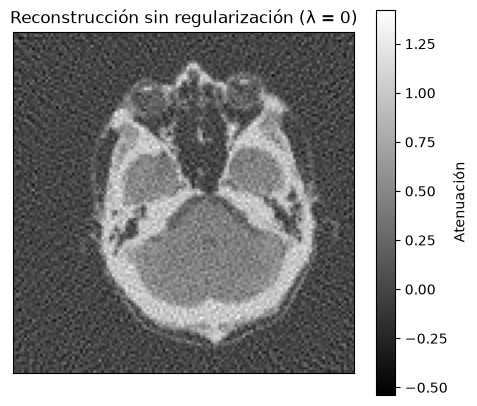

In [6]:
def aplicar_hessiana(v, lam):
    # Producto H v con H = AᵀA + lam DᵀD, sin armar H (sería de 16384 x 16384)
    return A.T @ (A @ v) + lam * (D.T @ (D @ v))


def mu_max(lam, max_iter=300, tol=1e-6):
    # Método de potencias (Clase 6): aproxima el autovalor más grande de H
    x = np.ones(n * n)                       # vector inicial cuya entrada más grande es 1
    u_anterior = 0
    for k in range(max_iter):
        Hx = aplicar_hessiana(x, lam)        # a. calcular H x_k
        u = Hx[np.argmax(np.abs(Hx))]        # b. u_k = entrada de H x_k con mayor valor absoluto
        x = Hx / u                           # c. x_(k+1) = (1/u_k) H x_k
        if abs(u - u_anterior) < tol * abs(u):   # se detiene cuando u_k deja de cambiar
            break
        u_anterior = u
    return u


def gd_regularizado(lam, alpha, tol=1e-7, max_iter=8000):
    x = np.zeros(n * n)                       # x0 = 0
    costo_anterior = None
    for t in range(1, max_iter + 1):
        r = A @ x - b
        Dx = D @ x
        costo = 0.5 * (r @ r + lam * (Dx @ Dx))
        # Criterio de parada: variación relativa del costo (no usa la imagen original, que es desconocida)
        if costo_anterior is not None and abs(costo_anterior - costo) / costo_anterior < tol:
            break
        costo_anterior = costo
        g = A.T @ r + lam * (D.T @ Dx)        # ∇J(x) = Aᵀ(Ax - b) + lam DᵀD x
        x = x - alpha * g
    return x, t


reconstrucciones = {}
registro = {}

lam = 0
alpha = 1 / mu_max(lam)
x, iteraciones = gd_regularizado(lam, alpha)
reconstrucciones[lam] = x
registro[lam] = {'alpha': alpha, 'iter': iteraciones}
print(f"mu_max = {1 / alpha:.1f}")
print(f"lambda = 0: alpha = {alpha:.2e}, iteraciones = {iteraciones}")

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(x.reshape(n, n), cmap='gray')
ax.set_title('Reconstrucción sin regularización (λ = 0)')
ax.set_xticks([])
ax.set_yticks([])
fig.colorbar(im, ax=ax, label='Atenuación')
plt.savefig('figuras/ejercicio_10d.png', dpi=150, bbox_inches='tight')
plt.show()

Se reutilizó el gradiente descendiente de los Ejercicios 8 y 9, partiendo de $x_0 = 0$.

 Como en el Ejercicio 8,la tasa de aprendizaje tiene que cumplir $0 < \alpha < 2/\mu_{\max}$, donde $\mu_{\max}$ es el mayor autovalor de la Hessiana $A^TA + \lambda D^TD$. En este caso la Hessiana es de $16384 \times 16384$, así que no conviene armarla ni usar `eigvalsh`. En su lugar, se calculó $\mu_{\max}$ con el método de potencias de la Clase 6, que solo necesita multiplicar la Hessiana por un vector. Ese producto se puede hacer sin armarla, como $A^T(Av) + \lambda D^T(Dv)$, y es barato porque $A$ y $D$ son dispersas. Se usó $\alpha = 1/\mu_{\max}$, que está dentro del intervalo.

El algoritmo se detiene cuando la variación del costo entre una iteración y la siguiente escercana a 0, o al llegar a un máximo de 8000 iteraciones. No se usa la imagen original, porque es desconocida.

Con $\lambda = 0$ el método llegó al máximo de iteraciones, la reconstrucción ya muestra la estructura de la imagen, se puede distinguir que es un craneo con su cerebro, pero se ve muy granulada, hay píxeles con valores muy distintos a sus vecinos y aparecen valores negativos, que no tienen sentido. Es el mismo efecto del ruido que se vio en los ejercicios 6 y 9.

#### e) Obtener reconstrucciones regularizadas minimizando $$J_\lambda(x) = \frac{1}{2}\left(\|Ax - b\|^2 + \lambda\,\|Dx\|^2\right)$$

##### Comenzar explorando $\lambda \in \{0.1,\ 1,\ 10,\ 30,\ 100\}$ y, si lo consideran necesario, probar valores adicionales.


#### f) Para cada reconstrucción, registrar $\lambda$, la tasa de aprendizaje, la cantidad de iteraciones, la norma del residuo $\|A\hat{x}_\lambda - b\|$, la medida de variación $\|D\hat{x}_\lambda\|$ y sus valores mínimo y máximo. Comparar la norma del residuo con la estimación del ruido incluida en los datos.

In [7]:
lambdas = [0.1, 1, 10, 30, 100]

for lam in lambdas:
    alpha = 1 / mu_max(lam)        # tasa estable: dentro de 0 < alpha < 2/mu_max (Ejercicio 8c)
    x, iteraciones = gd_regularizado(lam, alpha)
    reconstrucciones[lam] = x
    registro[lam] = {'alpha': alpha, 'iter': iteraciones}

print(f"Estimación de la norma del ruido: {norma_ruido:.2f}\n")
print(f"{'lambda':<8}{'alpha':>10}{'iter':>7}{'||Ax - b||':>12}{'||Dx||':>9}{'mín':>8}{'máx':>8}")
for lam in [0] + lambdas:
    x = reconstrucciones[lam]
    registro[lam]['residuo'] = np.linalg.norm(A @ x - b)
    registro[lam]['variacion'] = np.linalg.norm(D @ x)
    r = registro[lam]
    print(f"{lam:<8}{r['alpha']:>10.2e}{r['iter']:>7}{r['residuo']:>12.2f}{r['variacion']:>9.2f}{x.min():>8.3f}{x.max():>8.3f}")

Estimación de la norma del ruido: 75.97

lambda       alpha   iter  ||Ax - b||   ||Dx||     mín     máx
0         8.99e-05   8000       39.91    41.00  -0.536   1.425
0.1       8.99e-05   8000       40.51    37.38  -0.482   1.384
1         8.99e-05   7136       44.44    25.81  -0.285   1.218
10        8.99e-05   1053       55.41    18.49  -0.150   1.108
30        8.99e-05    482       71.58    15.11  -0.104   1.076
100       8.99e-05    271      102.71    11.46  -0.063   1.051


La tasa de aprendizaje es prácticamente la misma para todos los $\lambda$, porque el mayor autovalor de la Hessiana casi no cambia. Con $\lambda$ más grande el método necesitó menos iteraciones pero con $\lambda = 0$ y $0.1$ llegó al máximo de iteraciones posibles.

Al aumentar $\lambda$, el residuo crece y la variación $\|D\hat{x}_\lambda\|$ disminuye.Al igual que en el ejercicio 9 la reconstrucción se ajusta menos a las mediciones pero es más suave(saltos menos bruscos entre pixeles vecinos). Además, los valores negativos se reducen (de −0.54 a −0.06).

**Comparación con el ruido.** Las mediciones son $b = A\,x_{\text{real}} + \eta$, como en el ejercicio 6. Por lo tanto si se reconstruyera exactamente la imagen real, el residuo sería $\|A\,x_{\text{real}} - b\| = \|\eta\|$, es decir, la norma del ruido (≈ 76). Comparando con ese valor:

- con $\lambda = 0$, $0.1$, $1$ y $10$, el residuo (entre 40 y 55) es bastante menor que el ruido, es decir, la reconstrucción explica las mediciones mejor de lo que lo haría la imagen real, estto ocurre porque se está ajustando también al ruido.
- con $\lambda = 100$, el residuo (≈ 103) es mayor que el ruido, es decir, la reconstrucción deja sin explicar parte de la información real de las mediciones porque la suavidad pesa demasiado
- con $\lambda = 30$, el residuo (≈ 72) es el más cercano a la norma del ruido.

con $\lambda = 0$, $0.1$, $1$ y $10$, el residuo (entre 40 y 55) es bastante menor que el ruido, es decir, la reconstrucción explica las mediciones mejor de lo que lo haría la imagen real. Esto ocurre porque se está ajustando también al ruido;
- con $\lambda = 100$, el residuo (≈ 103) es mayor que el ruido, es decir, la reconstrucción deja sin explicar parte de la información real de las mediciones, porque la suavidad pesa demasiado(el lamda es tran grande que se termina suavizando ignorando importante)
- con $\lambda = 30$, el residuo (≈ 72) es el más cercano a la norma del ruido, es decir explica las mediciones hasta donde lo permite el ruido, sin ajustarse a él.

#### g) Elegir la reconstrucción que consideren más adecuada sin conocer la imagen original. Presentar una figura con el sinograma construido, la reconstrucción sin regularización y al menos tres reconstrucciones regularizadas, utilizando una escala de color común. Justificar la elección considerando el ruido, el residuo, y la preservación de estructuras en la imagen.

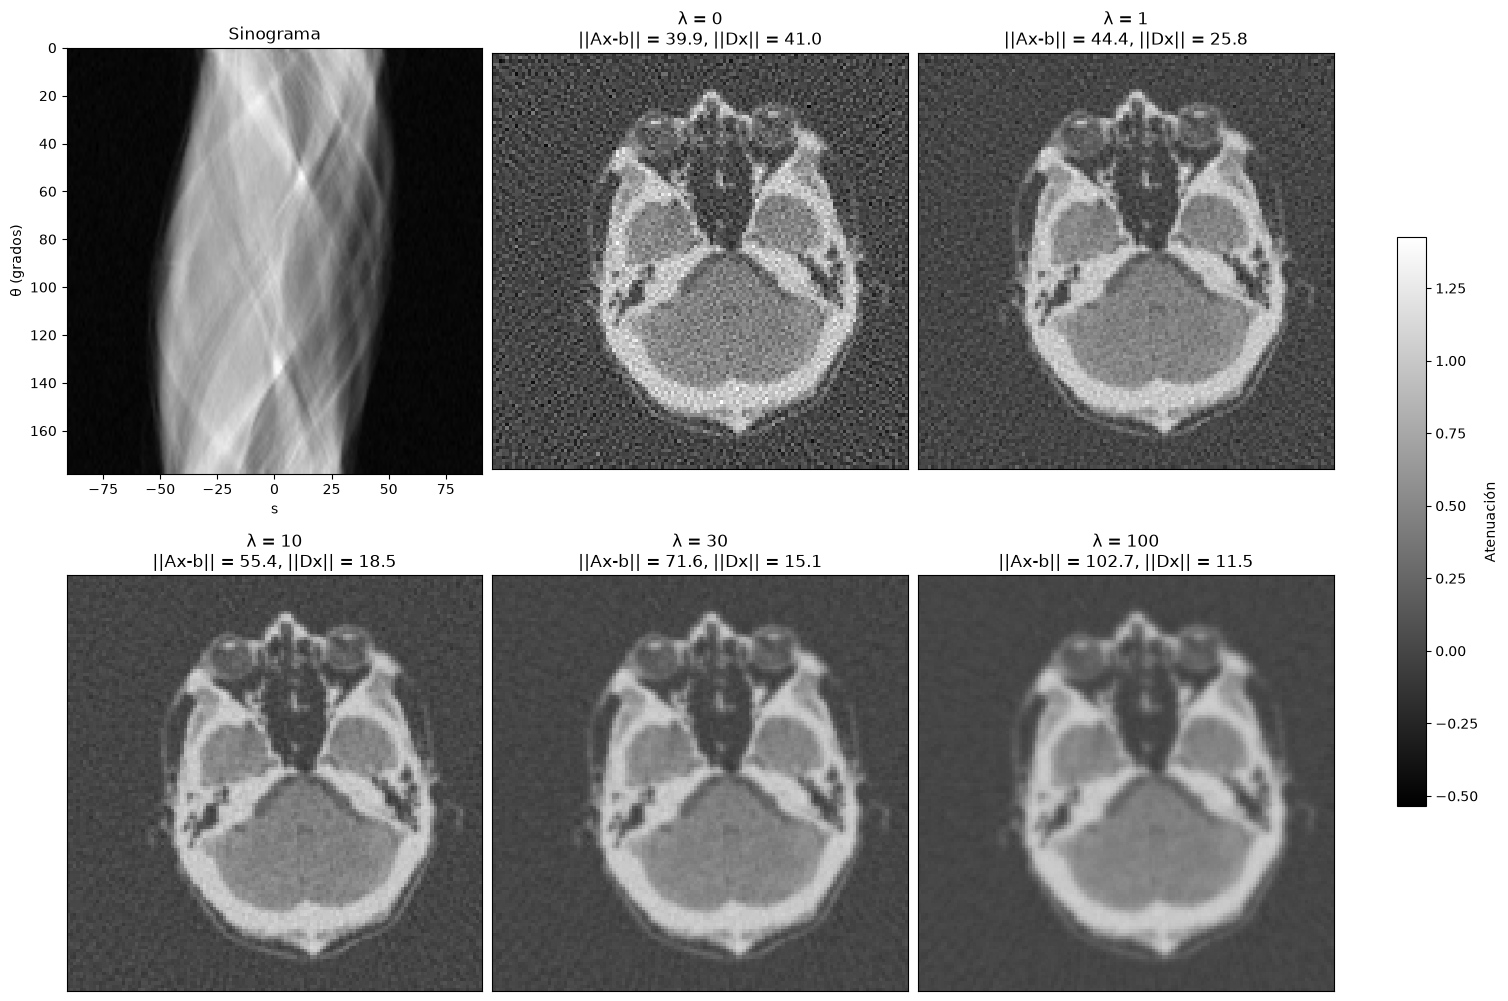

In [8]:
mostrar = [0, 1, 10, 30, 100]
imagenes = [reconstrucciones[l] for l in mostrar]
vmin = min(x.min() for x in imagenes)      # escala común para todas las reconstrucciones
vmax = max(x.max() for x in imagenes)

fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout='constrained')
axes = axes.ravel()

im_s = axes[0].imshow(S, cmap='gray', aspect='auto',
                      extent=[posiciones[0], posiciones[-1], np.degrees(angulos[-1]), np.degrees(angulos[0])])
axes[0].set_title('Sinograma')
axes[0].set_xlabel('s')
axes[0].set_ylabel('θ (grados)')

for ax, lam in zip(axes[1:], mostrar):
    r = registro[lam]
    im = ax.imshow(reconstrucciones[lam].reshape(n, n), cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(f"λ = {lam}\n||Ax-b|| = {r['residuo']:.1f}, ||Dx|| = {r['variacion']:.1f}")
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(im, ax=axes[1:], shrink=0.6, label='Atenuación')
plt.savefig('figuras/ejercicio_10g.png', dpi=150, bbox_inches='tight')
plt.show()

Sin conocer la imagen original, y luego de graficar las reconstrucciones, se eligió $\lambda = 1$, ya que al tratarse de una tomografía es importante poder distinguir detalles pequeños con precisión.

- **Ruido:** con $\lambda = 0$ el ruido es demasiado fuerte, el granulado se confunde con los pequenos detalles internos de la imagen y no permite distinguir bien qué es un componente real y qué es ruido. Con $\lambda = 1$ el granulado se reduce lo suficiente como para poder distinguir qué es ruido y qué es importante en la imagen. La variación $\|D\hat{x}\|$ baja de 41.0 a 25.8 y los valores negativos se reducen de ≈ −0.54 a ≈ −0.29. Todavía queda algo de granulado, sobre todo en el fondo, pero ya no impide distinguir las estructuras.
- **Preservación de estructuras:** es la reconstrucción en la que mejor se distinguen los contornos y los detalles internos. A partir de $\lambda = 10$ la imagen se suaviza más y empiezan a perderse detalles pequeños, que en una tomografía real podrían ser justamente algo importante de detectar.
- **Residuo:** el residuo (≈ 44.4) es menor que la norma del ruido (≈ 76), lo que indica que la reconstrucción todavía se ajusta a parte del ruido. Valores de $\lambda$ más grandes, como $30$, dan un residuo más cercano al ruido, pero a costa de suavizar la imagen y perder detalles.

Si nos basáramos solo en los resultados de la tabla, se podría pensar que la mejor opción es $\lambda = 30$, ya que, como se vio en el inciso anterior, es la que tiene el residuo más cercano a la norma del ruido. Sin embargo, al graficar las reconstrucciones y tener en cuenta que se trata de una tomografía, en la que los detalles pequeños pueden marcar la diferencia entre detectar una enfermedad o no, preferimos correr el riesgo de ajustarnos en parte al ruido antes que suavizar de más y perder información.